# Etap 3 — Przekształcanie i przygotowanie danych do analizy

**Cel:** poznanie podstawowych metod czyszczenia i formatowania danych oraz określenie ich wpływu na jakość analizy.
**Rezultat etapu:** oczyszczony i sformatowany zbiór danych zapisany w formacie CSV (`data/processed/`).

Plan:
1. Usuwanie duplikatów (oferty powtarzające się w kolejnych miesiącach, homonimy miast),
2. Poprawianie błędnych i nietypowych wartości, wartości odstające,
3. Standaryzacja formatów (nazwy miast, `yes/no` → `1/0`),
4. Uzupełnianie braków (imputacja),
5. Nowe atrybuty (cena za m², wiek budynku),
6. Dyskretyzacja (segmenty cenowe, strefy odległości, epoki budowy),
7. Normalizacja Min-Max,
8. Integracja zbiorów → wskaźniki dostępności per miasto,
9. Ocena wpływu jakości danych i zapis do CSV.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))
from src.utils import *  # ścieżki, wczytywanie danych, styl wykresów

set_plot_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import MinMaxScaler

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
sales_raw = load_apartments("sale")
rent_raw = load_apartments("rent")
cost_2024_raw = load_cost_2024()
cost_long_raw = load_cost_longitudinal()

# dziennik kroków czyszczenia — liczba wierszy po każdym kroku
log = {"sprzedaż": [("dane surowe", len(sales_raw))], "najem": [("dane surowe", len(rent_raw))]}
print(len(sales_raw), len(rent_raw))

195568 70847


## 3.1 Duplikaty

### a) Pełne duplikaty wierszy
Sprawdzamy wiersze identyczne we wszystkich kolumnach opisujących ofertę (bez nazwy pliku).

In [3]:
offer_cols = [c for c in sales_raw.columns if c not in ("source_file", "period")]
for name, df in [("sprzedaż", sales_raw), ("najem", rent_raw)]:
    print(f"{name}: pełne duplikaty w obrębie tego samego miesiąca = "
          f"{df.duplicated(subset=offer_cols + ['period']).sum()}, "
          f"ta sama oferta w kolejnych miesiącach = {df.duplicated(subset=['id']).sum():,}")

sprzedaż: pełne duplikaty w obrębie tego samego miesiąca = 0, ta sama oferta w kolejnych miesiącach = 102,601
najem: pełne duplikaty w obrębie tego samego miesiąca = 0, ta sama oferta w kolejnych miesiącach = 32,906


### b) Ta sama oferta w wielu miesiącach
Ogłoszenie wisi w serwisie zwykle kilka miesięcy, więc trafia do kilku plików miesięcznych. Do analizy przekrojowej
(jedna oferta = jedno mieszkanie) zostawiamy **ostatnią obserwację** każdej oferty (aktualna cena), a jako dodatkową informację zapisujemy
pierwszy i ostatni miesiąc obecności oraz zmianę ceny. Pełne dane miesięczne wykorzystamy do szeregu czasowego cen.

In [4]:
tmp = sales_raw.sort_values("period")
listing_history = tmp.groupby("id").agg(
    first_period=("period", "first"), last_period=("period", "last"),
    months_listed=("period", "nunique"), first_price=("price", "first"), last_price=("price", "last"))
listing_history["price_change_pct"] = (listing_history["last_price"] / listing_history["first_price"] - 1) * 100

print("Rozkład liczby miesięcy, przez które oferta była widoczna:")
print(listing_history["months_listed"].value_counts().sort_index().to_dict())
changed = listing_history.query("months_listed > 1")
print(f"Oferty widoczne >1 mies.: {len(changed):,}; z nich zmieniło cenę: {(changed['price_change_pct'] != 0).mean():.1%}; "
      f"mediana zmiany (gdy była): {changed.loc[changed['price_change_pct'] != 0, 'price_change_pct'].median():.1f}%")

Rozkład liczby miesięcy, przez które oferta była widoczna:
{1: 47620, 2: 21369, 3: 10708, 4: 5709, 5: 2764, 6: 1650, 7: 1263, 8: 615, 9: 429, 10: 332, 11: 508}
Oferty widoczne >1 mies.: 45,347; z nich zmieniło cenę: 28.3%; mediana zmiany (gdy była): -3.1%


### c) Duplikaty w zbiorze kosztów życia
W etapie 2 wykryliśmy, że nazwa miasta nie jest unikalna (homonimy w różnych województwach). To **nie są** błędne duplikaty, tylko różne miasta —
nie usuwamy ich, ale tworzymy unikalny klucz `city_key = miasto|województwo`.

In [5]:
def clean_cost(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["city"] = out["city"].str.strip()
    out["city_norm"] = out["city"].map(normalize_city)
    out["city_key"] = out["city_norm"] + "|" + out["voivodeship"].map(normalize_city)
    return out

cost_2024 = clean_cost(cost_2024_raw)
cost_long = clean_cost(cost_long_raw)
print("Pełne duplikaty (2024):", cost_2024_raw.duplicated().sum(), "| (2010–2024):", cost_long_raw.duplicated().sum())
print("Duplikaty klucza city_key (2024):", cost_2024["city_key"].duplicated().sum())
print("Duplikaty (city_key, year) w szeregu:", cost_long.duplicated(["city_key", "year"]).sum())
print("Braki danych (2024):", cost_2024.isna().sum().sum(), "| (2010–2024):", cost_long.isna().sum().sum())

Pełne duplikaty (2024): 0 | (2010–2024): 0
Duplikaty klucza city_key (2024): 0
Duplikaty (city_key, year) w szeregu: 0
Braki danych (2024): 0 | (2010–2024): 0


## 3.2 Błędne i nietypowe wartości

Reguły poprawności (walidacja dziedzinowa):
- piętro nie może być wyższe niż liczba pięter budynku → `floor = NaN` (do imputacji),
- powierzchnia na pokój < 10 m² jest nierealna (np. 25 m² i 6 pokoi) → usunięcie oferty,
- forma własności `udział` (12 ofert) oznacza sprzedaż części mieszkania → cena nieporównywalna → usunięcie,
- najem: czynsz < 500 PLN/mies. to najpewniej błąd (np. podana kaucja lub cena za dobę) → usunięcie.

In [6]:
def fix_invalid(df: pd.DataFrame, kind: str) -> pd.DataFrame:
    out = df.copy()
    bad_floor = out["floor"] > out["floorCount"]
    out.loc[bad_floor, "floor"] = np.nan
    print(f"  piętro > liczba pięter: {bad_floor.sum():,} → floor = NaN")

    too_small = out["squareMeters"] / out["rooms"] < 10
    share = out["ownership"].eq("udział")
    mask = too_small | share
    if kind == "rent":
        cheap = out["price"] < 500
        print(f"  czynsz < 500 PLN: {cheap.sum():,}")
        mask |= cheap
    print(f"  < 10 m² na pokój: {too_small.sum():,}, udział: {share.sum():,} → usunięto łącznie {mask.sum():,}")
    return out[~mask]

print("Sprzedaż:"); sales = fix_invalid(sales_raw, "sale")
log["sprzedaż"].append(("błędne wartości", len(sales)))
print("Najem:"); rent = fix_invalid(rent_raw, "rent")
log["najem"].append(("błędne wartości", len(rent)))

Sprzedaż:
  piętro > liczba pięter: 0 → floor = NaN
  < 10 m² na pokój: 19, udział: 12 → usunięto łącznie 31
Najem:
  piętro > liczba pięter: 0 → floor = NaN
  czynsz < 500 PLN: 88
  < 10 m² na pokój: 1, udział: 0 → usunięto łącznie 89


### Wartości odstające ceny za m²
Ceny różnią się bardzo między miastami, więc granice wartości odstających liczymy **osobno w każdym mieście** metodą IQR:
oferta jest odstająca, gdy cena za m² < Q1 − 1,5·IQR lub > Q3 + 1,5·IQR.

In [7]:
def remove_outliers(df: pd.DataFrame, k: float = 1.5) -> pd.DataFrame:
    out = df.copy()
    out["price_per_m2"] = out["price"] / out["squareMeters"]
    q = out.groupby("city")["price_per_m2"].quantile([0.25, 0.75]).unstack()
    q["low"] = q[0.25] - k * (q[0.75] - q[0.25])
    q["high"] = q[0.75] + k * (q[0.75] - q[0.25])
    bounds = out["city"].map(q["low"]), out["city"].map(q["high"])
    keep = out["price_per_m2"].between(*bounds)
    print(f"  usunięto wartości odstające: {(~keep).sum():,} ({(~keep).mean():.1%})")
    return out[keep], q[["low", "high"]]

print("Sprzedaż:"); sales, sale_bounds = remove_outliers(sales)
log["sprzedaż"].append(("wartości odstające", len(sales)))
print("Najem:"); rent, rent_bounds = remove_outliers(rent)
log["najem"].append(("wartości odstające", len(rent)))

sale_bounds.index = [city_label(c) for c in sale_bounds.index]
sale_bounds.round(0).T

Sprzedaż:


  usunięto wartości odstające: 3,742 (1.9%)
Najem:
  usunięto wartości odstające: 1,408 (2.0%)


,Białystok,Bydgoszcz,Częstochowa,Gdańsk,Gdynia,Katowice,Kraków,Łódź,Lublin,Poznań,Radom,Rzeszów,Szczecin,Warszawa,Wrocław
low,"3,873.00","3,095.00","3,033.00","2,813.00","2,987.00","2,299.00","5,933.00","3,628.00","4,231.00","5,067.00","3,653.00","3,764.00","2,679.00","5,965.00","5,755.00"
high,"14,309.00","12,334.00","10,004.00","25,477.00","21,689.00","14,254.00","25,240.00","12,522.00","14,251.00","16,355.00","9,271.00","16,172.00","14,848.00","28,154.00","19,494.00"


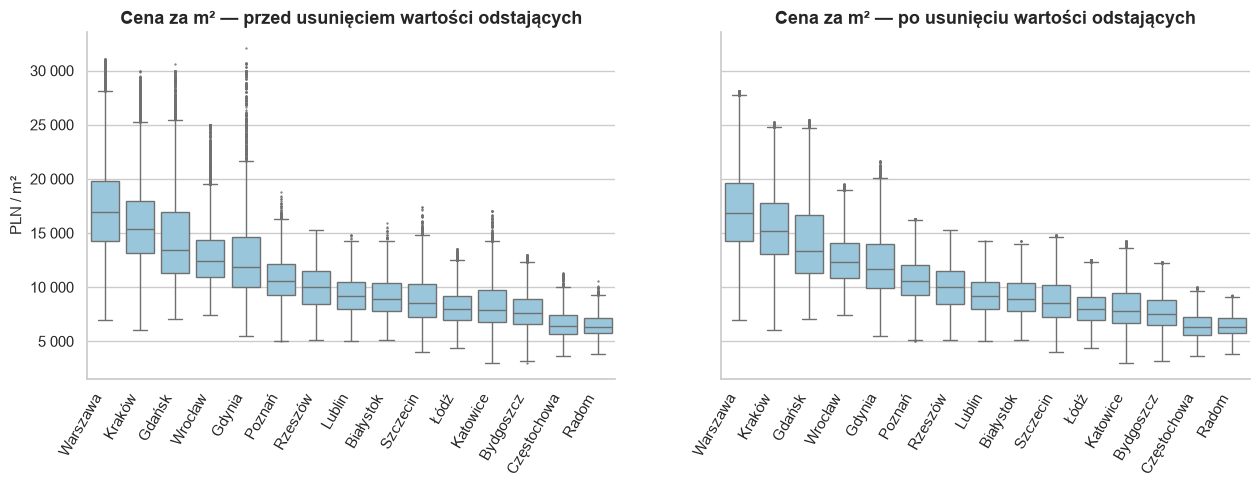

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
before = sales_raw.assign(price_per_m2=sales_raw["price"] / sales_raw["squareMeters"])
order = before.groupby("city")["price_per_m2"].median().sort_values(ascending=False).index
for ax, data, title in [(axes[0], before, "przed usunięciem wartości odstających"),
                        (axes[1], sales, "po usunięciu wartości odstających")]:
    sns.boxplot(data=data, x="city", y="price_per_m2", order=order, ax=ax, color="#8ecae6", fliersize=0.6)
    ax.set_xticks(range(len(order)), [city_label(c) for c in order], rotation=60, ha="right")
    ax.set_title(f"Cena za m² — {title}")
    ax.set_xlabel("")
    ax.set_ylabel("PLN / m²")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(thousands))
save_fig(fig, "03_wartosci_odstajace")
plt.show()

## 3.3 Szereg czasowy cen (przed deduplikacją)
Mediana ceny za m² w każdym miesiącu i mieście — na podstawie wszystkich obserwacji miesięcznych (po usunięciu błędów i wartości odstających).

In [9]:
monthly = pd.concat([
    sales.groupby(["city", "period"])["price_per_m2"].agg(["median", "size"]).add_prefix("sale_"),
    rent.groupby(["city", "period"])["price_per_m2"].agg(["median", "size"]).add_prefix("rent_"),
], axis=1).reset_index()
monthly.columns = ["city", "period", "mediana_cena_m2", "liczba_ofert_sprzedaz", "mediana_czynsz_m2", "liczba_ofert_najem"]
monthly["period"] = monthly["period"].astype(str)
monthly["city_label"] = monthly["city"].map(city_label)
monthly.head()

,city,period,mediana_cena_m2,liczba_ofert_sprzedaz,mediana_czynsz_m2,liczba_ofert_najem,city_label
0,bialystok,2023-08,"8,150.58",262,NaN,NaN,Białystok
1,bialystok,2023-09,"8,168.03",308,NaN,NaN,Białystok
2,bialystok,2023-10,"8,307.47",258,NaN,NaN,Białystok
3,bialystok,2023-11,"8,517.48",237,43.86,51.00,Białystok
4,bialystok,2023-12,"8,915.11",226,43.86,50.00,Białystok


## 3.4 Deduplikacja ofert
Zostawiamy ostatnią obserwację każdej oferty i dołączamy historię (pierwszy/ostatni miesiąc, liczba miesięcy, zmiana ceny).

In [10]:
def deduplicate(df: pd.DataFrame) -> pd.DataFrame:
    df = df.sort_values("period")
    hist = df.groupby("id").agg(first_period=("period", "first"), months_listed=("period", "nunique"),
                                first_price=("price", "first"))
    last = df.drop_duplicates("id", keep="last").set_index("id")
    last = last.join(hist)
    last["price_change_pct"] = (last["price"] / last["first_price"] - 1) * 100
    return last.drop(columns=["first_price", "source_file"]).rename(columns={"period": "last_period"}).reset_index()

sales = deduplicate(sales)
rent = deduplicate(rent)
log["sprzedaż"].append(("deduplikacja (unikalne oferty)", len(sales)))
log["najem"].append(("deduplikacja (unikalne oferty)", len(rent)))
print(f"Sprzedaż: {len(sales):,} unikalnych ofert | najem: {len(rent):,}")

Sprzedaż: 91,292 unikalnych ofert | najem: 37,250


## 3.5 Standaryzacja formatów
- `city` — już w formie znormalizowanej (małe litery, bez polskich znaków); dodajemy czytelną etykietę `city_label`,
- atrybuty binarne `yes/no` → `1/0` (typ liczbowy, gotowy do modeli),
- okresy jako tekst `RRRR-MM`.

In [11]:
BINARY = ["hasParkingSpace", "hasBalcony", "hasElevator", "hasSecurity", "hasStorageRoom"]

def standardize(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["city"] = out["city"].map(normalize_city)
    out["city_label"] = out["city"].map(city_label)
    for col in BINARY:
        out[col] = out[col].map({"yes": 1, "no": 0})
    for col in ["last_period", "first_period"]:
        out[col] = out[col].astype(str)
    return out

sales = standardize(sales)
rent = standardize(rent)
sales[["city", "city_label"] + BINARY].head(3)

,city,city_label,hasParkingSpace,hasBalcony,hasElevator,hasSecurity,hasStorageRoom
0,szczecin,Szczecin,1,1,1.00,0,1
1,warszawa,Warszawa,0,0,0.00,0,1
2,warszawa,Warszawa,0,0,1.00,0,1


## 3.6 Uzupełnianie braków (imputacja)

| Atrybut | Braki | Metoda | Uzasadnienie |
|---|---|---|---|
| `condition`, `buildingMaterial`, `type` | 20–75% | nowa kategoria `brak_danych` | braków jest za dużo, by je zgadywać; brak informacji też niesie treść |
| `buildYear` | ~17% | **regresja** (las losowy) | najmniejszy błąd w porównaniu z etapu 2 |
| `floorCount` | ~1% | mediana w grupie (miasto × typ zabudowy) | mało braków, wartość zależy od typu budynku |
| `floor` | ~18% | mediana w mieście, przycięta do `floorCount` | piętro nie może przekraczać wysokości budynku |
| `hasElevator` | ~5% | reguła: budynek ≥ 5 pięter → winda | wymóg z przepisów budowlanych |
| odległości do POI | < 3% | mediana w mieście | rozkład skośny → mediana |

In [12]:
def impute(df: pd.DataFrame, label: str) -> pd.DataFrame:
    out = df.copy()
    missing_before = out.isna().sum()

    for col in ["condition", "buildingMaterial", "type"]:
        out[col] = out[col].fillna("brak_danych")

    out["floorCount"] = out["floorCount"].fillna(out.groupby(["city", "type"])["floorCount"].transform("median"))
    out["floorCount"] = out["floorCount"].fillna(out["floorCount"].median())

    out["floor"] = out["floor"].fillna(out.groupby("city")["floor"].transform("median"))
    out["floor"] = np.minimum(out["floor"], out["floorCount"])

    elevator_rule = (out["floorCount"] >= 5).astype(int)
    out["hasElevator"] = out["hasElevator"].fillna(elevator_rule).astype(int)

    dist_cols = [c for c in out.columns if c.endswith("Distance") and c != "centreDistance"]
    for col in dist_cols:
        out[col] = out[col].fillna(out.groupby("city")[col].transform("median"))

    # regresja dla roku budowy
    feats = ["floorCount", "centreDistance", "poiCount", "price_per_m2", "squareMeters", "latitude", "longitude",
             "hasElevator", "hasParkingSpace"]
    X = out[feats].assign(type_code=out["type"].astype("category").cat.codes)
    known = out["buildYear"].notna()
    model = RandomForestRegressor(n_estimators=80, max_depth=16, n_jobs=-1, random_state=RANDOM_STATE)
    model.fit(X[known], out.loc[known, "buildYear"])
    out["buildYear_imputed"] = (~known).astype(int)
    out.loc[~known, "buildYear"] = model.predict(X[~known]).round()

    report = pd.DataFrame({"braki przed": missing_before, "braki po": out.isna().sum()})
    report = report[report["braki przed"] > 0]
    print(f"{label}: uzupełniono {int(report['braki przed'].sum() - report['braki po'].sum()):,} brakujących wartości")
    return out, report

sales, sales_missing = impute(sales, "Sprzedaż")
rent, rent_missing = impute(rent, "Najem")
sales_missing

Sprzedaż: uzupełniono 166,533 brakujących wartości


Najem: uzupełniono 70,237 brakujących wartości


,braki przed,braki po
buildYear,"15,296.00",0
buildingMaterial,"38,652.00",0
clinicDistance,322.00,0
collegeDistance,"2,471.00",0
condition,"68,663.00",0
floor,"15,745.00",0
floorCount,"1,013.00",0
hasElevator,"4,338.00",0
kindergartenDistance,78.00,0
pharmacyDistance,121.00,0


## 3.7 Nowe atrybuty
- `price_per_m2` — cena za m² (sprzedaż: PLN/m², najem: PLN/m²/mies.),
- `building_age` — wiek budynku w 2024 r.,
- `floor_ratio` — względna wysokość piętra (0 = parter, 1 = ostatnie piętro),
- `amenities_count` — liczba udogodnień (suma atrybutów binarnych),
- `price_index_city` — cena za m² względem mediany miasta (100 = typowa cena w tym mieście); pozwala porównywać oferty z różnych miast.

In [13]:
def add_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["price_per_m2"] = out["price"] / out["squareMeters"]
    out["building_age"] = 2024 - out["buildYear"]
    out["floor_ratio"] = np.where(out["floorCount"] > 0, out["floor"] / out["floorCount"], 0).clip(0, 1)
    out["amenities_count"] = out[BINARY].sum(axis=1)
    # indeks ceny względem miasta: 100 = mediana ceny za m² w danym mieście
    out["price_index_city"] = out["price_per_m2"] / out.groupby("city")["price_per_m2"].transform("median") * 100
    return out

sales = add_features(sales)
rent = add_features(rent)
sales[["price", "squareMeters", "price_per_m2", "buildYear", "building_age", "floor", "floorCount", "floor_ratio", "amenities_count"]].describe().T

,count,mean,std,min,25%,50%,75%,max
price,"91,292.00","757,805.77","382,664.01","150,000.00","517,385.00","680,000.00","890,000.00","3,250,000.00"
squareMeters,"91,292.00",56.51,20.24,25.00,42.50,52.70,65.20,150.00
price_per_m2,"91,292.00","13,569.73","4,687.31","3,011.63","9,985.04","13,191.49","16,666.67","28,153.38"
buildYear,"91,292.00","1,984.83",31.51,"1,850.00","1,969.00","1,985.00","2,013.00","2,024.00"
building_age,"91,292.00",39.17,31.51,0.00,11.00,39.00,55.00,174.00
floor,"91,292.00",3.28,2.34,1.00,2.00,3.00,4.00,29.00
floorCount,"91,292.00",5.44,3.30,1.00,3.00,4.00,7.00,29.00
floor_ratio,"91,292.00",0.65,0.29,0.04,0.40,0.70,1.00,1.00
amenities_count,"91,292.00",1.90,1.08,0.00,1.00,2.00,3.00,5.00


## 3.8 Dyskretyzacja

**Dyskretyzacja** to zamiana atrybutu ciągłego na skończoną liczbę przedziałów (kategorii). Stosujemy dwie metody:
- **równoliczne przedziały (kwantyle)** — każdy przedział ma tyle samo obserwacji → `segment_cenowy` (terciles ceny za m²: *tanie / średnie / drogie*),
- **przedziały wyznaczone wiedzą dziedzinową** → `strefa` (odległość od centrum: *centrum* < 2 km, *pośrednia* 2–5 km, *peryferia* > 5 km),
  `epoka_budowy` (*przedwojenne* < 1945, *PRL* 1945–1989, *1990–2009*, *2010+*), `wielkosc` (*małe* < 40 m², *średnie* 40–60, *duże* 60–90, *bardzo duże* > 90).

Segment cenowy liczymy **względem miasta** (tercyle w obrębie miasta) — „drogie w Radomiu” i „drogie w Warszawie” to inne kwoty.

In [14]:
def discretize(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["segment_cenowy"] = out.groupby("city")["price_per_m2"].transform(
        lambda s: pd.qcut(s, 3, labels=["tanie", "średnie", "drogie"])).astype(str)
    out["strefa"] = pd.cut(out["centreDistance"], [-np.inf, 2, 5, np.inf],
                           labels=["centrum", "pośrednia", "peryferia"]).astype(str)
    out["epoka_budowy"] = pd.cut(out["buildYear"], [-np.inf, 1944, 1989, 2009, np.inf],
                                 labels=["przedwojenne", "PRL", "1990–2009", "2010+"]).astype(str)
    out["wielkosc"] = pd.cut(out["squareMeters"], [0, 40, 60, 90, np.inf],
                             labels=["małe", "średnie", "duże", "bardzo duże"]).astype(str)
    return out

sales = discretize(sales)
rent = discretize(rent)
for col in ["segment_cenowy", "strefa", "epoka_budowy", "wielkosc"]:
    print(f"{col}: {sales[col].value_counts().to_dict()}")

segment_cenowy: {'tanie': 30574, 'drogie': 30409, 'średnie': 30309}
strefa: {'peryferia': 37692, 'pośrednia': 34730, 'centrum': 18870}
epoka_budowy: {'PRL': 37240, '2010+': 27323, '1990–2009': 16407, 'przedwojenne': 10322}
wielkosc: {'średnie': 40956, 'duże': 25162, 'małe': 18924, 'bardzo duże': 6250}


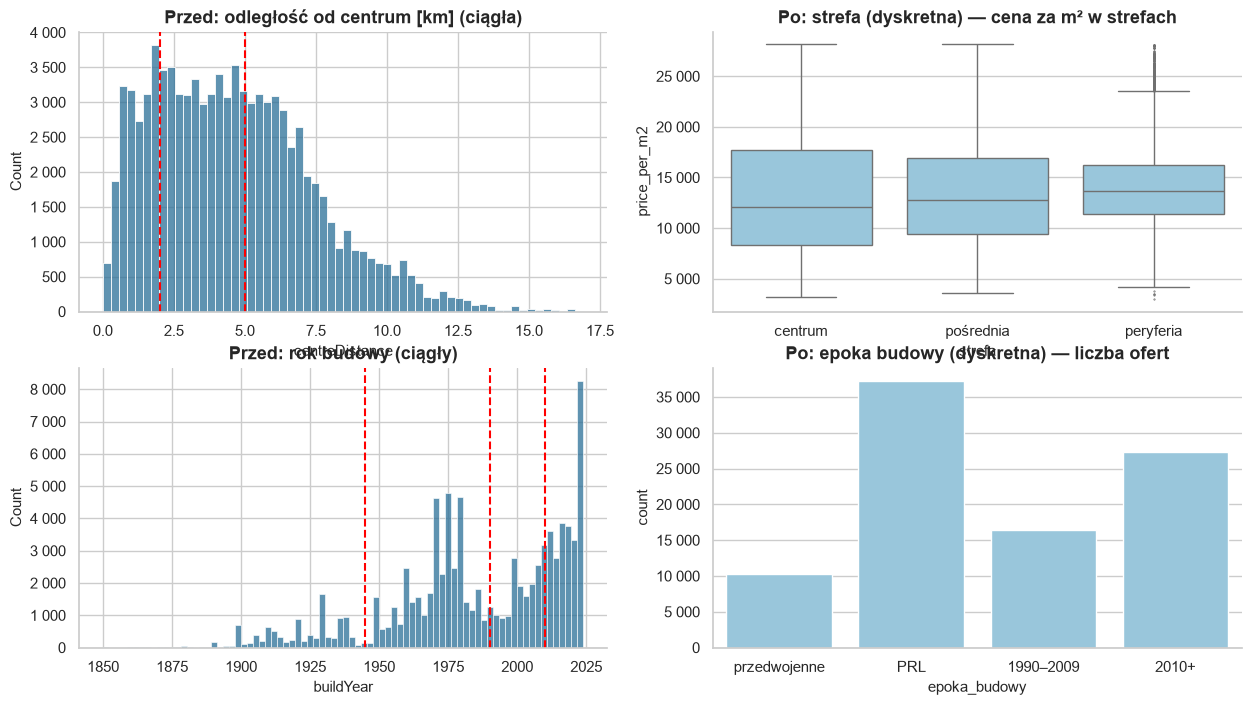

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
sns.histplot(sales["centreDistance"], bins=60, ax=axes[0, 0], color="#2a6f97")
for b in [2, 5]:
    axes[0, 0].axvline(b, color="red", ls="--")
axes[0, 0].set_title("Przed: odległość od centrum [km] (ciągła)")
order_z = ["centrum", "pośrednia", "peryferia"]
sns.boxplot(data=sales, x="strefa", y="price_per_m2", order=order_z, ax=axes[0, 1], color="#8ecae6", fliersize=0.5)
axes[0, 1].set_title("Po: strefa (dyskretna) — cena za m² w strefach")
sns.histplot(sales["buildYear"], bins=80, ax=axes[1, 0], color="#2a6f97")
for b in [1945, 1990, 2010]:
    axes[1, 0].axvline(b, color="red", ls="--")
axes[1, 0].set_title("Przed: rok budowy (ciągły)")
order_e = ["przedwojenne", "PRL", "1990–2009", "2010+"]
sns.countplot(data=sales, x="epoka_budowy", order=order_e, ax=axes[1, 1], color="#8ecae6")
axes[1, 1].set_title("Po: epoka budowy (dyskretna) — liczba ofert")
for ax in axes.flat:
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(thousands))
save_fig(fig, "03_dyskretyzacja")
plt.show()

In [16]:
# mediana indeksu ceny względem miasta (100 = mediana miasta) — usuwa efekt różnic cen między miastami
pd.crosstab(sales["epoka_budowy"], sales["strefa"], values=sales["price_index_city"], aggfunc="median") \
  .reindex(index=order_e, columns=order_z).round(0)

strefa,centrum,pośrednia,peryferia
epoka_budowy,,,
przedwojenne,100.00,97.00,93.00
PRL,105.00,97.00,89.00
1990–2009,108.00,100.00,90.00
2010+,138.00,120.00,104.00


Po dyskretyzacji widać wzorce trudne do odczytania z danych ciągłych: najdroższe są mieszkania **nowe w centrum** (ok. 38% powyżej mediany miasta),
a najtańsze — starsze budynki (PRL, 1990–2009) na **peryferiach** (ok. 10% poniżej mediany). Porównujemy indeks względem miasta, bo surowe ceny
mieszałyby efekt strefy z efektem miasta (w Warszawie jest najwięcej ofert peryferyjnych i jednocześnie najwyższe ceny).
Tracimy jednak część informacji (np. różnicę między 2,1 a 4,9 km) — dlatego w modelach (etap 5) używamy wersji ciągłych, a dyskretnych do raportowania i wizualizacji.

## 3.9 Normalizacja Min-Max

**Normalizacja** sprowadza atrybuty liczbowe do wspólnej skali, żeby atrybuty o dużych wartościach (cena ~10⁵) nie dominowały nad atrybutami o małych (odległość ~1 km).
Ma to kluczowe znaczenie dla metod opartych na odległościach (K-means, grupowanie hierarchiczne) oraz PCA.

**Min-Max:** $x' = \dfrac{x - x_{min}}{x_{max} - x_{min}}$ → wartości w przedziale [0, 1], kształt rozkładu bez zmian.

In [17]:
NUMERIC_FEATURES = ["price", "price_per_m2", "squareMeters", "rooms", "floor", "floorCount", "buildYear",
                    "centreDistance", "poiCount", "schoolDistance", "clinicDistance", "postOfficeDistance",
                    "kindergartenDistance", "restaurantDistance", "collegeDistance", "pharmacyDistance",
                    "floor_ratio", "amenities_count"]

scaler = MinMaxScaler()
sales_norm = sales[["id", "city"]].copy()
sales_norm[NUMERIC_FEATURES] = scaler.fit_transform(sales[NUMERIC_FEATURES]).round(5)

compare = pd.DataFrame({
    "min przed": sales[NUMERIC_FEATURES].min(), "max przed": sales[NUMERIC_FEATURES].max(),
    "średnia przed": sales[NUMERIC_FEATURES].mean(),
    "min po": sales_norm[NUMERIC_FEATURES].min(), "max po": sales_norm[NUMERIC_FEATURES].max(),
    "średnia po": sales_norm[NUMERIC_FEATURES].mean(),
})
compare

,min przed,max przed,średnia przed,min po,max po,średnia po
price,"150,000.00","3,250,000.00","757,805.77",0.00,1.00,0.20
price_per_m2,"3,011.63","28,153.38","13,569.73",0.00,1.00,0.42
squareMeters,25.00,150.00,56.51,0.00,1.00,0.25
rooms,1.00,6.00,2.61,0.00,1.00,0.32
floor,1.00,29.00,3.28,0.00,1.00,0.08
floorCount,1.00,29.00,5.44,0.00,1.00,0.16
buildYear,"1,850.00","2,024.00","1,984.83",0.00,1.00,0.77
centreDistance,0.01,16.92,4.62,0.00,1.00,0.27
poiCount,0.00,212.00,19.59,0.00,1.00,0.09
schoolDistance,0.00,4.95,0.41,0.00,1.00,0.08


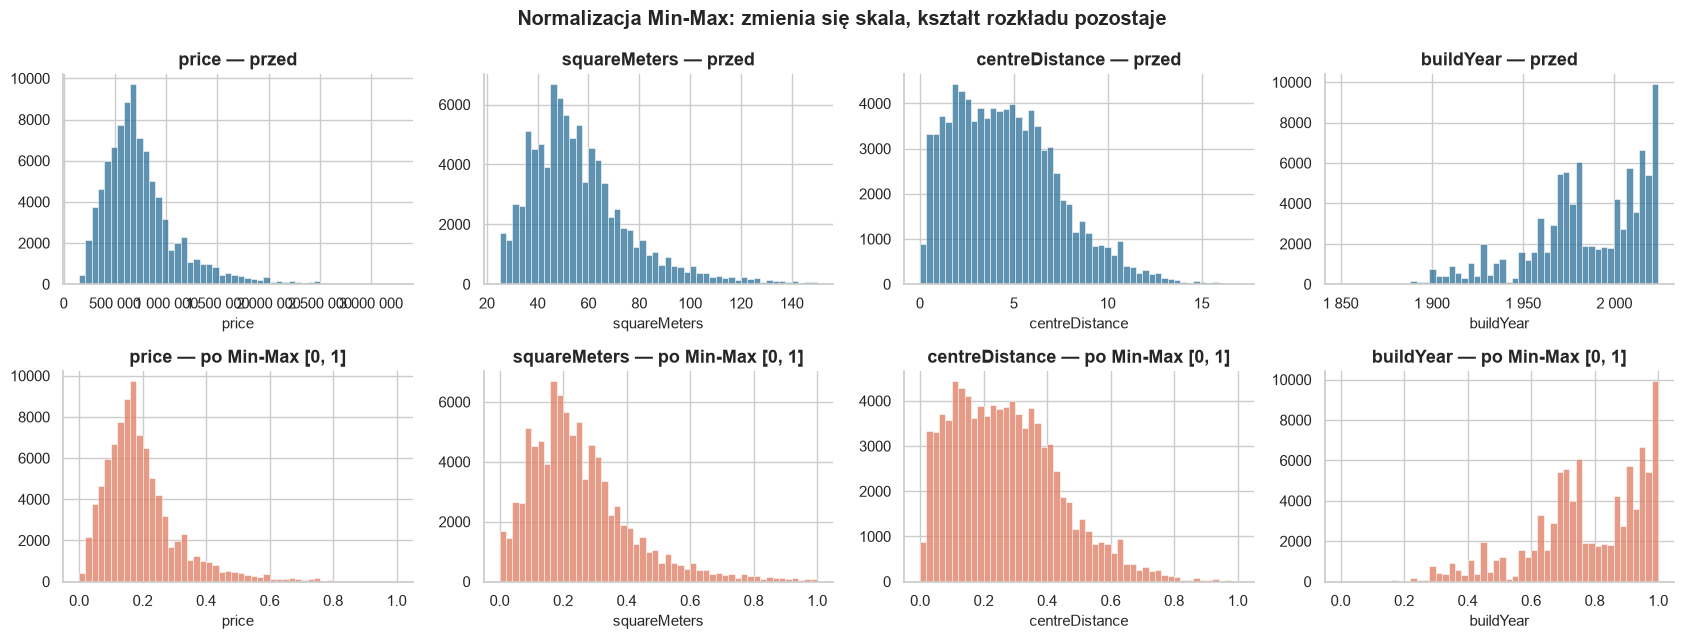

In [18]:
cols = ["price", "squareMeters", "centreDistance", "buildYear"]
fig, axes = plt.subplots(2, 4, figsize=(17, 6.5))
for i, col in enumerate(cols):
    sns.histplot(sales[col], bins=50, ax=axes[0, i], color="#2a6f97")
    axes[0, i].set_title(f"{col} — przed")
    sns.histplot(sales_norm[col], bins=50, ax=axes[1, i], color="#e07a5f")
    axes[1, i].set_title(f"{col} — po Min-Max [0, 1]")
    axes[0, i].xaxis.set_major_formatter(mticker.FuncFormatter(thousands))
    for ax in axes[:, i]:
        ax.set_ylabel("")
fig.suptitle("Normalizacja Min-Max: zmienia się skala, kształt rozkładu pozostaje", fontweight="bold")
fig.tight_layout()
save_fig(fig, "03_normalizacja_minmax")
plt.show()

## 3.10 Integracja zbiorów — wskaźniki dostępności per miasto

Łączymy oba źródła po znormalizowanej nazwie miasta. Dla każdego z 15 miast wyznaczamy:

| Wskaźnik | Wzór |
|---|---|
| `cena_50m2` | mediana ceny za m² × 50 |
| `miesiace_pensji_50m2` | cena 50 m² / mediana pensji netto |
| `lata_oszczedzania_30proc` | cena 50 m² / (30% pensji netto × 12) |
| `koszty_bez_mieszkania` | koszt życia singla − czynsz 1-pok. (zbiór 2) |
| `dochod_dyspozycyjny` | pensja netto − koszty bez mieszkania |
| `lata_wklad20_30proc_pensji` | 20% ceny 50 m² / (30% pensji netto × 12) |
| `lata_wklad20_50proc_dysp` | 20% ceny 50 m² / (50% dochodu dyspozycyjnego × 12) |
| `czynsz_50m2` | mediana czynszu za m² × 50 (oferty najmu) |
| `rentownosc_brutto_proc` | roczny czynsz za m² / cena za m² × 100 |
| `cena_do_czynszu_lata` | cena za m² / roczny czynsz za m² (*price-to-rent*) |
| `czynsz_do_pensji_proc` | czynsz 50 m² / pensja netto × 100 |
| `m2_za_pensje` | pensja netto / cena za m² |

In [19]:
sale_city = sales.groupby("city").agg(
    liczba_ofert_sprzedaz=("id", "size"), mediana_cena=("price", "median"),
    mediana_cena_m2=("price_per_m2", "median"), mediana_metraz=("squareMeters", "median"),
    mediana_rok_budowy=("buildYear", "median"), mediana_odl_centrum=("centreDistance", "median"),
    udzial_nowych_proc=("epoka_budowy", lambda s: (s == "2010+").mean() * 100))
rent_city = rent.groupby("city").agg(
    liczba_ofert_najem=("id", "size"), mediana_czynsz=("price", "median"), mediana_czynsz_m2=("price_per_m2", "median"))

c24 = cost_2024[cost_2024["city_norm"].isin(CITY_LABELS)].drop_duplicates("city_norm").set_index("city_norm")
c24 = c24[["city", "voivodeship", "city_tier", "population_approx", "avg_salary_gross_pln", "median_salary_gross_pln",
           "median_salary_net_pln", "cost_of_living_index", "rent_1br_outside_center_pln", "groceries_monthly_pln",
           "public_transport_monthly_pln", "est_monthly_cost_single_pln"]]

long_big = cost_long[cost_long["city_norm"].isin(CITY_LABELS)]
salary_wide = long_big.pivot_table(index="city_norm", columns="year", values="median_salary_net_pln")
c24["pensja_netto_2019"] = salary_wide[2019]
c24["wzrost_pensji_2019_2024_proc"] = (salary_wide[2024] / salary_wide[2019] - 1) * 100

price_wide = monthly.pivot_table(index="city", columns="period", values="mediana_cena_m2")
first_m, last_m = "2023-08", "2024-06"
dynamics = ((price_wide[last_m] / price_wide[first_m] - 1) * 100).rename("zmiana_ceny_m2_2023_08_2024_06_proc")

cities = sale_city.join(rent_city).join(c24).join(dynamics)
cities.index.name = "city_key"

net = cities["median_salary_net_pln"]
cities["cena_50m2"] = cities["mediana_cena_m2"] * 50
cities["miesiace_pensji_50m2"] = cities["cena_50m2"] / net
cities["lata_oszczedzania_30proc"] = cities["cena_50m2"] / (0.3 * net * 12)
cities["koszty_bez_mieszkania"] = cities["est_monthly_cost_single_pln"] - cities["rent_1br_outside_center_pln"]
cities["dochod_dyspozycyjny"] = net - cities["koszty_bez_mieszkania"]
cities["lata_wklad20_30proc_pensji"] = 0.2 * cities["cena_50m2"] / (0.3 * net * 12)
cities["lata_wklad20_50proc_dysp"] = 0.2 * cities["cena_50m2"] / (0.5 * cities["dochod_dyspozycyjny"] * 12)
cities["czynsz_50m2"] = cities["mediana_czynsz_m2"] * 50
cities["rentownosc_brutto_proc"] = cities["mediana_czynsz_m2"] * 12 / cities["mediana_cena_m2"] * 100
cities["cena_do_czynszu_lata"] = cities["mediana_cena_m2"] / (cities["mediana_czynsz_m2"] * 12)
cities["czynsz_do_pensji_proc"] = cities["czynsz_50m2"] / net * 100
cities["m2_za_pensje"] = net / cities["mediana_cena_m2"]
cities = cities.rename(columns={"city": "miasto"}).reset_index()

show = ["miasto", "mediana_cena_m2", "median_salary_net_pln", "cena_50m2", "miesiace_pensji_50m2",
        "lata_oszczedzania_30proc", "dochod_dyspozycyjny", "lata_wklad20_30proc_pensji", "lata_wklad20_50proc_dysp",
        "rentownosc_brutto_proc", "czynsz_do_pensji_proc"]
cities[show].sort_values("miesiace_pensji_50m2", ascending=False)

,miasto,mediana_cena_m2,median_salary_net_pln,cena_50m2,miesiace_pensji_50m2,lata_oszczedzania_30proc,dochod_dyspozycyjny,lata_wklad20_30proc_pensji,lata_wklad20_50proc_dysp,rentownosc_brutto_proc,czynsz_do_pensji_proc
13,Warszawa,"16,695.29",5893,"834,764.69",141.65,39.35,3198,7.87,8.70,5.61,66.18
6,Kraków,"14,945.96",5566,"747,298.23",134.26,37.29,2810,7.46,8.86,5.14,57.55
3,Gdańsk,"13,166.65",5457,"658,332.50",120.64,33.51,2635,6.70,8.33,5.90,59.29
11,Rzeszów,"9,975.24",4365,"498,762.08",114.26,31.74,1634,6.35,10.17,6.13,58.38
4,Gdynia,"11,500.00",5239,"575,000.00",109.75,30.49,2549,6.10,7.52,5.70,52.17
14,Wrocław,"12,306.43",5675,"615,321.36",108.43,30.12,2949,6.02,6.96,5.96,53.82
8,Lublin,"9,202.45",4365,"460,122.70",105.41,29.28,1658,5.86,9.25,6.56,57.58
0,Białystok,"9,000.00",4311,"450,000.00",104.38,29.00,1638,5.80,9.16,5.76,50.12
9,Poznań,"10,593.22",5348,"529,661.02",99.04,27.51,2613,5.50,6.76,5.89,48.62
12,Szczecin,"8,808.82",4584,"440,441.18",96.08,26.69,1819,5.34,8.07,6.99,55.94


## 3.11 Wpływ jakości danych na wyniki

Porównujemy wyniki dla danych **surowych** i **oczyszczonych**. Na danych surowych każda oferta wisząca np. 6 miesięcy liczy się 6 razy,
a błędne i skrajne wartości zawyżają średnie.

In [20]:
raw_ppm = sales_raw.assign(ppm=sales_raw["price"] / sales_raw["squareMeters"])
quality = pd.DataFrame({
    "średnia surowe": raw_ppm.groupby("city")["ppm"].mean(),
    "średnia oczyszczone": sales.groupby("city")["price_per_m2"].mean(),
    "mediana surowe": raw_ppm.groupby("city")["ppm"].median(),
    "mediana oczyszczone": sales.groupby("city")["price_per_m2"].median(),
})
quality["różnica średnich [%]"] = (quality["średnia surowe"] / quality["średnia oczyszczone"] - 1) * 100
quality["różnica median [%]"] = (quality["mediana surowe"] / quality["mediana oczyszczone"] - 1) * 100
quality.index = [city_label(c) for c in quality.index]
quality.sort_values("różnica średnich [%]", ascending=False).round(1)

,średnia surowe,średnia oczyszczone,mediana surowe,mediana oczyszczone,różnica średnich [%],różnica median [%]
Gdynia,"12,850.50","12,005.60","11,891.40","11,500.00",7.00,3.40
Kraków,"15,982.90","15,361.40","15,357.10","14,946.00",4.00,2.80
Gdańsk,"14,536.30","14,093.90","13,421.90","13,166.60",3.10,1.90
Wrocław,"12,897.10","12,571.80","12,413.80","12,306.40",2.60,0.90
Częstochowa,"6,620.00","6,465.70","6,391.80","6,313.30",2.40,1.20
Warszawa,"17,333.50","17,038.00","16,899.90","16,695.30",1.70,1.20
Katowice,"8,452.10","8,329.40","7,886.00","7,899.00",1.50,-0.20
Radom,"6,524.60","6,472.00","6,325.50","6,294.60",0.80,0.50
Bydgoszcz,"7,785.50","7,732.70","7,578.90","7,559.60",0.70,0.30
Łódź,"8,183.60","8,130.20","7,969.50","7,963.00",0.70,0.10


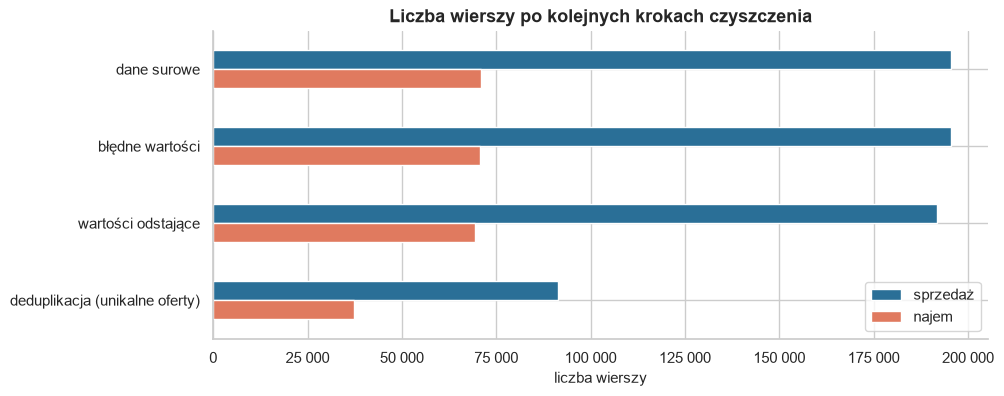

,sprzedaż,najem
krok,,
dane surowe,195568,70847
błędne wartości,195537,70758
wartości odstające,191795,69350
deduplikacja (unikalne oferty),91292,37250


In [21]:
funnel = pd.concat({k: pd.DataFrame(v, columns=["krok", "wiersze"]).set_index("krok")["wiersze"] for k, v in log.items()}, axis=1)
fig, ax = plt.subplots(figsize=(10, 4))
funnel.plot(kind="barh", ax=ax, color=["#2a6f97", "#e07a5f"])
ax.invert_yaxis()
ax.set_title("Liczba wierszy po kolejnych krokach czyszczenia")
ax.set_xlabel("liczba wierszy")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(thousands))
save_fig(fig, "03_lejek_czyszczenia")
plt.show()
funnel

**Wnioski o jakości danych:**
- Ponad połowa wierszy surowych to **powtórzenia tych samych ofert** w kolejnych miesiącach — bez deduplikacji oferty długo niesprzedane (często przeszacowane) miałyby nieproporcjonalnie duży wpływ na statystyki.
- Wartości odstające i błędy w większym stopniu zmieniają **średnią** niż **medianę** — to potwierdza wybór mediany jako miary typowej.
- Imputacja zamiast usuwania wierszy z brakami pozwoliła zachować wszystkie oferty (usunięcie wierszy z jakimkolwiek brakiem skasowałoby **~88%** unikalnych ofert, bo `condition` ma 75% braków).

## 3.12 Zapis oczyszczonych danych (CSV)

In [22]:
outputs = {
    "oferty_sprzedaz_clean.csv": sales,
    "oferty_najem_clean.csv": rent,
    "oferty_sprzedaz_minmax.csv": sales_norm,
    "ceny_miesieczne.csv": monthly,
    "miasta_wskazniki.csv": cities,
    "koszty_zycia_2024_clean.csv": cost_2024,
    "koszty_zycia_2010_2024_clean.csv": cost_long,
}
for name, df in outputs.items():
    path = PROCESSED_DIR / name
    df.to_csv(path, index=False)
    print(f"{name:38s} {df.shape[0]:>7,} × {df.shape[1]:<3} {path.stat().st_size / 1024**2:6.1f} MB")

oferty_sprzedaz_clean.csv               91,292 × 43    27.5 MB


oferty_najem_clean.csv                  37,250 × 43    11.1 MB


oferty_sprzedaz_minmax.csv              91,292 × 20    15.0 MB
ceny_miesieczne.csv                        165 × 7      0.0 MB
miasta_wskazniki.csv                        15 × 38     0.0 MB
koszty_zycia_2024_clean.csv                295 × 21     0.0 MB
koszty_zycia_2010_2024_clean.csv         2,745 × 24     0.4 MB


## 3.13 Podsumowanie etapu

- Usunięto powtórzenia ofert (195,6 tys. wierszy → 91,3 tys. unikalnych ofert sprzedaży; najem 70,8 tys. → 37,3 tys.), błędne wartości i wartości odstające (IQR per miasto).
- Ujednolicono formaty (nazwy miast, `yes/no` → `1/0`), uzupełniono braki metodami dopasowanymi do typu atrybutu (regresja dla `buildYear`, kategoria `brak_danych` dla atrybutów kategorycznych).
- Utworzono nowe atrybuty (cena za m², wiek budynku, liczba udogodnień), wersje zdyskretyzowane (segment cenowy, strefa, epoka budowy, wielkość) i znormalizowane metodą Min-Max.
- Połączono oba źródła w tabelę **`miasta_wskazniki.csv`** ze wskaźnikami dostępności — podstawę do odpowiedzi na pytania analityczne oraz do grupowania miast.
- Oczyszczone zbiory zapisano w `data/processed/` w formacie CSV.